COU 07506 Digital Signal Processing  

Week 04: z-Transform Laboratory: Poles, Zeros and Stability

Name: NASONI JOEL RICHARD

Registration No: 240242468221

Class: BENG24COE

Group: 03

Date: 24/11/2026

Instructor checkpoints signed:

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

Task 4.1 — A pole-zero plotting function

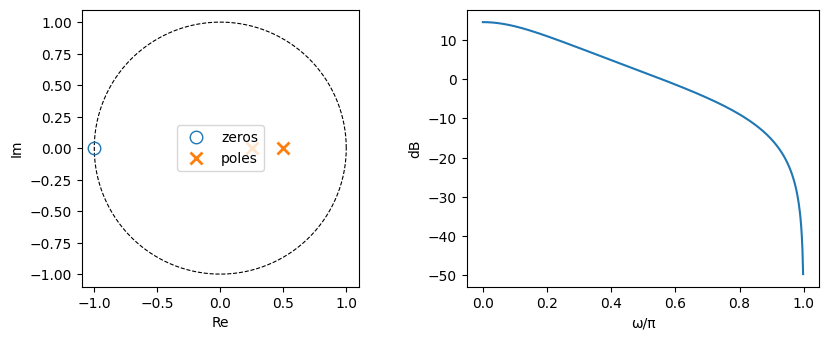

poles: [0.5  0.25]  stable: True


In [8]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Re")
    ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))

z, p = zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_xlabel("ω/π")
ax2.set_ylabel("dB")

plt.show()

print("poles:", p, " stable:", np.all(np.abs(p) < 1))

Task 4.2 — Inverse z-transform with residuez.

In [9]:
r, p, k = signal.residuez([1], [1, -0.75, 0.125])

print("residues", r, "poles", p)

n = np.arange(10)
x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

impulse = np.zeros(10)
impulse[0] = 1

x_lf = signal.lfilter([1], [1, -0.75, 0.125], impulse)

print(np.allclose(x_pf, x_lf))

residues [-1.  2.] poles [0.25 0.5 ]
True


In [10]:
r, p, k = signal.residuez([1, 1], [1, -0.75, 0.125])

n = np.arange(10)
h_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real

impulse = np.zeros(10)
impulse[0] = 1

h_lf = signal.lfilter([1, 1], [1, -0.75, 0.125], impulse)

print("residues:", r)
print("poles:", p)
print("Match:", np.allclose(h_pf, h_lf))

residues: [-5.  6.]
poles: [0.25 0.5 ]
Match: True


Task 4.3 — Pole position and impulse response

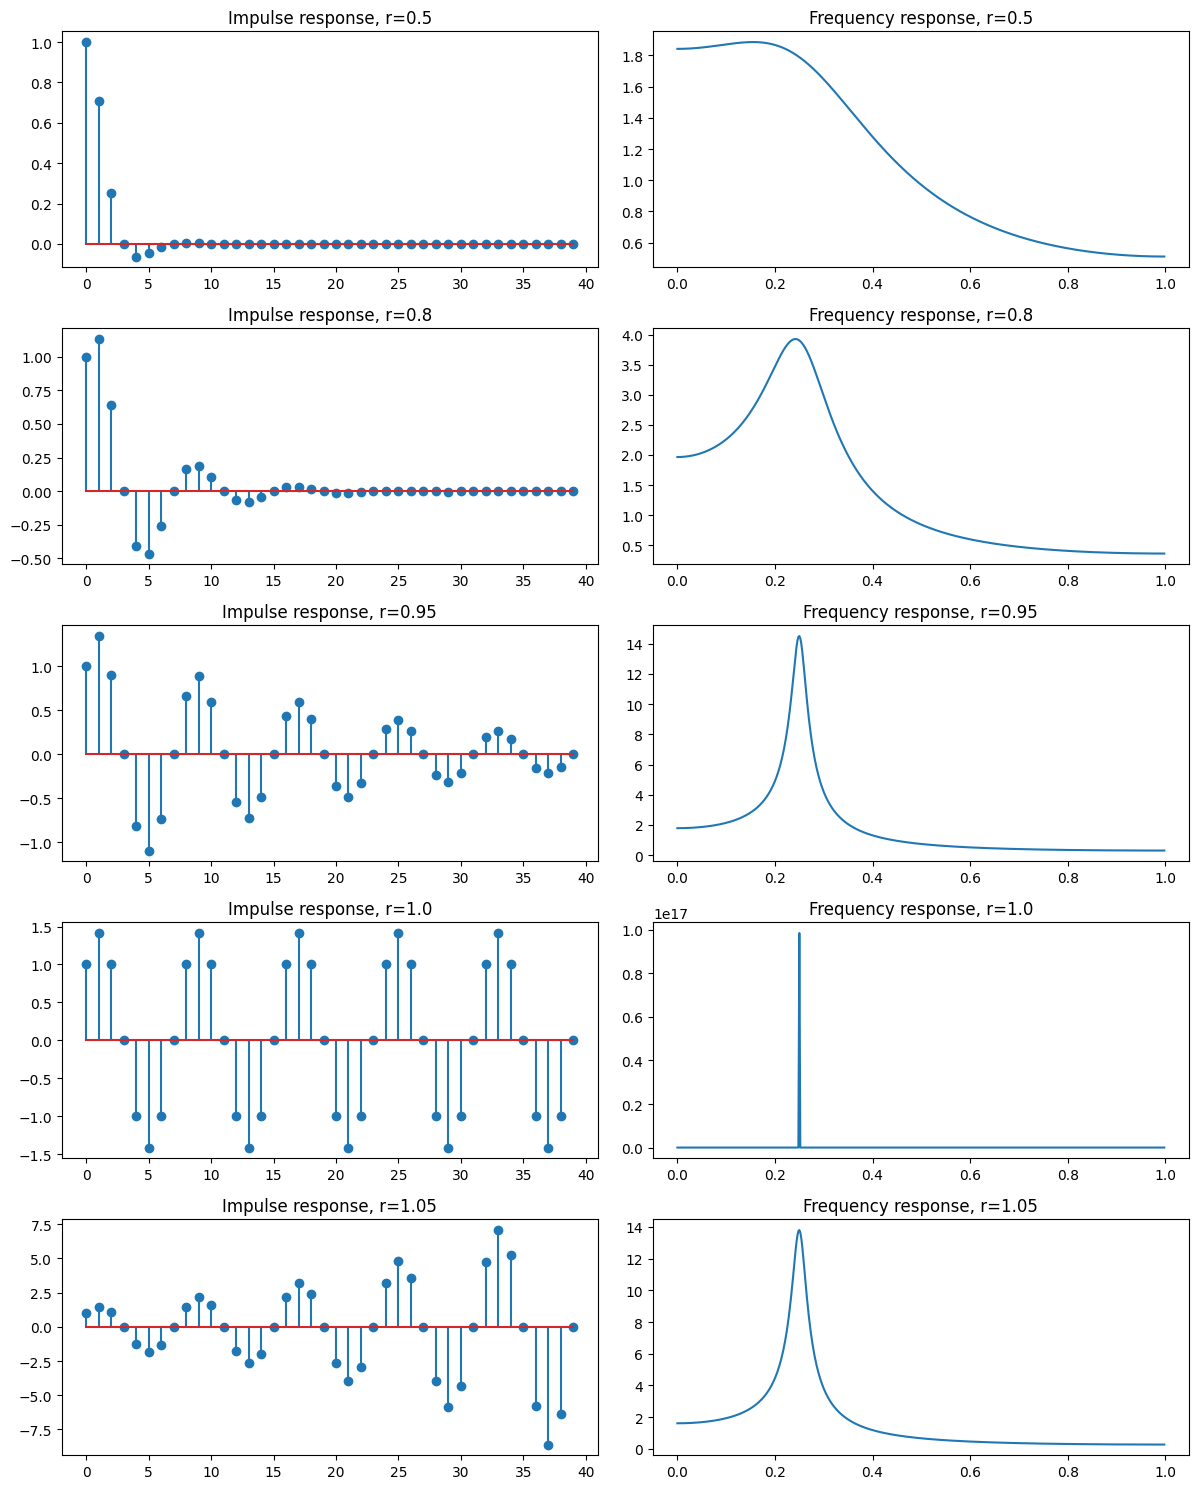

In [11]:
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]
theta = np.pi / 4
n = np.arange(40)

fig, axes = plt.subplots(5, 2, figsize=(12, 15))

for i, r in enumerate(r_values):
    a = [1, -2*r*np.cos(theta), r**2]
    b = [1]

    h = signal.lfilter(b, a, np.r_[1, np.zeros(39)])
    w, H = signal.freqz(b, a, worN=512)

    axes[i, 0].stem(n, h)
    axes[i, 0].set_title(f"Impulse response, r={r}")

    axes[i, 1].plot(w/np.pi, np.abs(H))
    axes[i, 1].set_title(f"Frequency response, r={r}")

plt.tight_layout()
plt.show()

Task 4.4 — Stability of given systems

In [14]:
systems = {
    "H1": ([1], [1, -1.6, 0.89]),
    "H2": ([1, 1], [1, -2.5, 1]),
    "H3": ([1], [1, 0.5, -0.5]),
    "H4": ([1, 0, 0, 0, -1], [1])
}

for name, (b, a) in systems.items():
    z, p, k = signal.tf2zpk(b, a)
    stable = np.all(np.abs(p) < 1)
    print(name, "poles:", p, "stable:", stable)

H1 poles: [0.8+0.5j 0.8-0.5j] stable: True
H2 poles: [2.  0.5] stable: False
H3 poles: [-1.   0.5] stable: False
H4 poles: [] stable: True


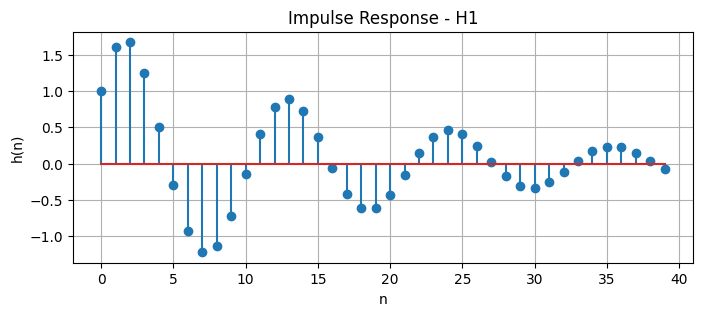

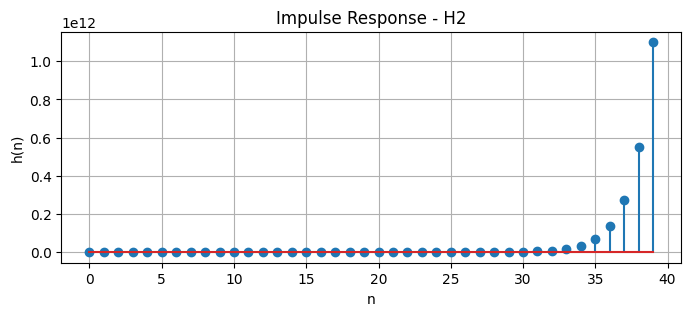

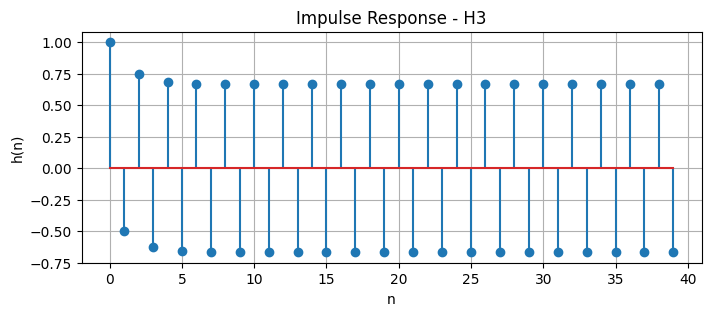

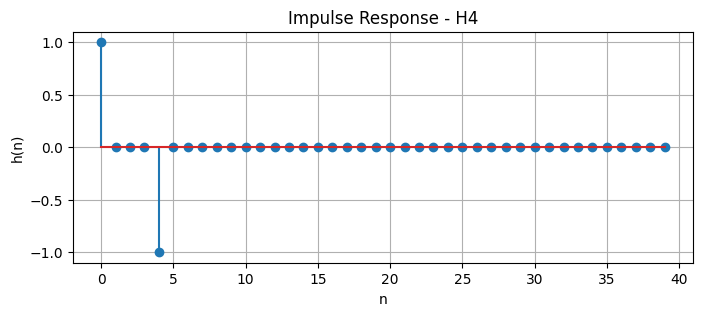

In [15]:
n = np.arange(40)
impulse = np.zeros(40)
impulse[0] = 1

for name, (b, a) in systems.items():
    h = signal.lfilter(b, a, impulse)

    plt.figure(figsize=(8, 3))
    plt.stem(n, h)
    plt.title(f"Impulse Response - {name}")
    plt.xlabel("n")
    plt.ylabel("h(n)")
    plt.grid()
    plt.show()

Task 4.5 — Design a resonator

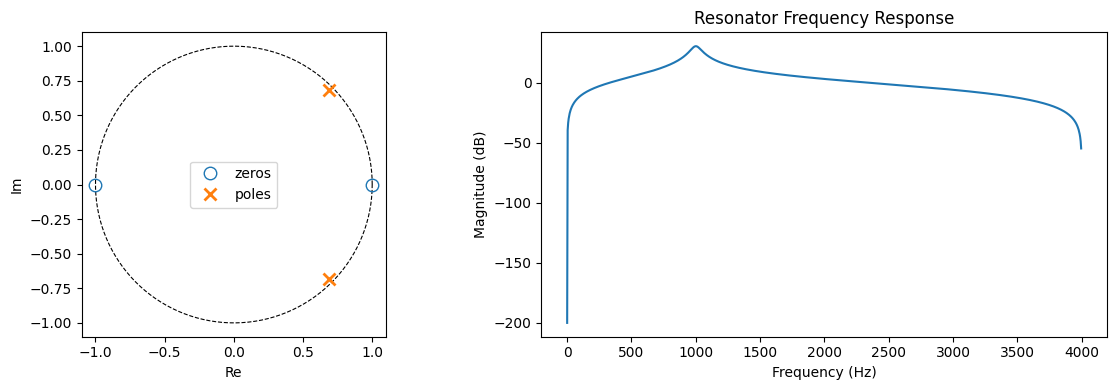

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]
Stable: True


In [16]:
fs = 8000
f0 = 1000
r = 0.97

theta = 2 * np.pi * f0 / fs

b = [1, 0, -1]
a = [1, -2*r*np.cos(theta), r**2]

z, p, k = signal.tf2zpk(b, a)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

zplane(b, a, ax1)

w, H = signal.freqz(b, a, worN=1024, fs=fs)

ax2.plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-10)))
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.set_title("Resonator Frequency Response")

plt.tight_layout()
plt.show()

print("Zeros:", z)
print("Poles:", p)
print("Stable:", np.all(np.abs(p) < 1))

In [17]:
from IPython.display import Audio, display

rng = np.random.default_rng(0)
x = rng.standard_normal(8000)

y = signal.lfilter(b, a, x)

display(Audio(y, rate=8000))

**Analysis Question**

**1. Explain the effect of r on the bandwidth of resonance in Task 4.3**

As r approaches 1, the resonance becomes sharper and the bandwidth becomes narrower. Smaller values of r produce wider bandwidths.

**2. What happens to h(n) when a pole lies exactly on the unit circle?**

The impulse response does not decay to zero. The system is marginally stable and is not BIBO stable.

**3. Why do zeros at z = ±1 make the resonator a band-pass filter?**

The zero at z = 1 blocks DC (0 Hz), while the zero at z = -1 blocks the Nyquist frequency (fs/2). Therefore, frequencies between these points can pass.

**4. Use the stability triangle to check answers to Task 4.4 (a)–(c).**

- H1: Stable because both poles have magnitude less than 1.
- H2: Unstable because one pole is outside the unit circle.
- H3: Unstable because one pole lies exactly on the unit circle.